In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import matplotlib.lines as mlines
from statsmodels.regression.linear_model import yule_walker
from spectrum import pyule, aryule, pburg, arburg
from scipy.signal import windows
from scipy.linalg import toeplitz
from statsmodels.tsa.ar_model import AutoReg

rc({"text.usetex": True
    ,
    'family': 'serif', 'serif': ['Computer Modern'],
    })

plt.rcParams.update({'font.size': 12})

In [3]:
def YW(data, order):
    'ni ok!?'
    dim=len(data)
    A = np.zeros(shape=(order,order)) # order=p
    b = np.zeros(shape=(order))
    #K = np.zeros(shape=(order,order))

    R = autocorrelation(data,order)
    for i in range(order):#row
        for j in range(order):#column
            k=abs(i-j)
            A[i,j] = R[k]
            #K[i,j] = k
        k = i
        b[i] = -R[k]

    a_k = np.linalg.solve(A,b)
    G2 = R[0] + np.dot(a_k,R)
    G = np.sqrt(abs(G2))
    print('G: ',G2,G)
    return a_k, G
def autocorrelation(data, order):
    'ni ok!?'
    dim=len(data)
    R = np.zeros(shape=(order))
    for k in range(order):
        r=0
        for n in range(dim):
            r+= data[n] * data[n-k]
        R[k] = r / (dim - k)
    return R
def napoved_dat(data, order, n_predict, preslikaj=0, burg=False):
    '''aryule, upošteva G'''
    dim=len(data)
    if burg:
        a_k, G, _ = arburg(data, order=order)
    else:
        #a_k, G = yule_walker(data, order, method='adjusted') #adjusted=default, mle=maximum-likehood estimator
        a_k, G, _ = aryule(data, order) #minus pred S_n, podoben rez.
        #a_k, G = YW(data, order) #ni ok
    #print('G: ', G)
    z =  np.roots(np.concatenate(([1], -a_k))) #poli (ničle v imenovalcu)
    for i in range(len(z)):
        r=np.abs(z[i])
        if r>1 and preslikaj != 0:
            if preslikaj==1:
                z[i] = 1 / z[i].conjugate() #mirror
            else:
                z[i] = z[i] / np.abs(z[i]) #on unit circle
    if preslikaj != 0:
        A = np.zeros((order, order), dtype=np.complex128)
        b = np.ones(order)
        for i in range(order):
            for j in range(order):
                A[i, j] = z[j] ** -(i + 1)
        a_k = np.linalg.solve(A, b) #corrected

    prediction = np.array(data)
    for n in range(n_predict):
        S_n = -G*prediction[n] #aryule
        #S_n=0 #yule_walker
        for k in range(order):
            S_n += a_k[k] * prediction[-k-1]
        #S_n = -np.dot(a_k, prediction[-order:]) #+ G*prediction[n]
        prediction = np.append(prediction, -S_n)
    return prediction[-n_predict:], z
def napoved_dat_yw(data, order, n_predict, preslikaj=0, method='adjusted'):
    ''' Yule Walker
    method: adjusted=default, mle=maximum-likehood estimator. Način avtokorelacije!
    G ni upoštrevan - ne deluje!'''
    dim=len(data)
    a_k, G = yule_walker(data, order, method=method) #adjusted=default, mle=maximum-likehood estimator
    #print('G: ', G)
    z =  np.roots(np.concatenate(([1], -a_k))) #poli (ničle v imenovalcu)
    for i in range(len(z)):
        r=np.abs(z[i])
        if r>1 and preslikaj != 0:
            if preslikaj==1:
                z[i] = 1 / z[i].conjugate() #mirror
            else:
                z[i] = z[i] / np.abs(z[i]) #on unit circle
    if preslikaj != 0:
        A = np.zeros((order, order), dtype=np.complex128)
        b = np.ones(order)
        for i in range(order):
            for j in range(order):
                A[i, j] = z[j] ** -(i + 1)
        a_k = np.linalg.solve(A, b) #corrected

    prediction = np.array(data)
    for n in range(n_predict):
        #S_n = -G*prediction[n] #aryule
        S_n=0 #yule_walker
        for k in range(order):
            S_n += a_k[k] * prediction[-k-1]
        #S_n = -np.dot(a_k, prediction[-order:]) #+ G*prediction[n]
        prediction = np.append(prediction, S_n)
    return prediction[-n_predict:], z
def napoved_AutoReg(train, order, n_predict):
    # train autoregression
    model = AutoReg(train, lags=order) #conditional-maximum-likehood estimation!
    model_fit = model.fit()
    # make predictions
    predictions = model_fit.predict(start=len(train), end=len(train)+n_predict-1, dynamic=False)
    return predictions
def PSD_MME(data, order, okno=None):
    '''iz datoteke 12.nal.ipynb'''
    dim= len(data)
    
    if okno is not None:
        window = getattr(windows, okno)(dim)
        data = data * window

    p = pyule(data, order=order)
    p.run()
    px = p.get_converted_psd(sides='onesided')/dim
    #fx = p.frequencies(sides='onesided')        
    return px

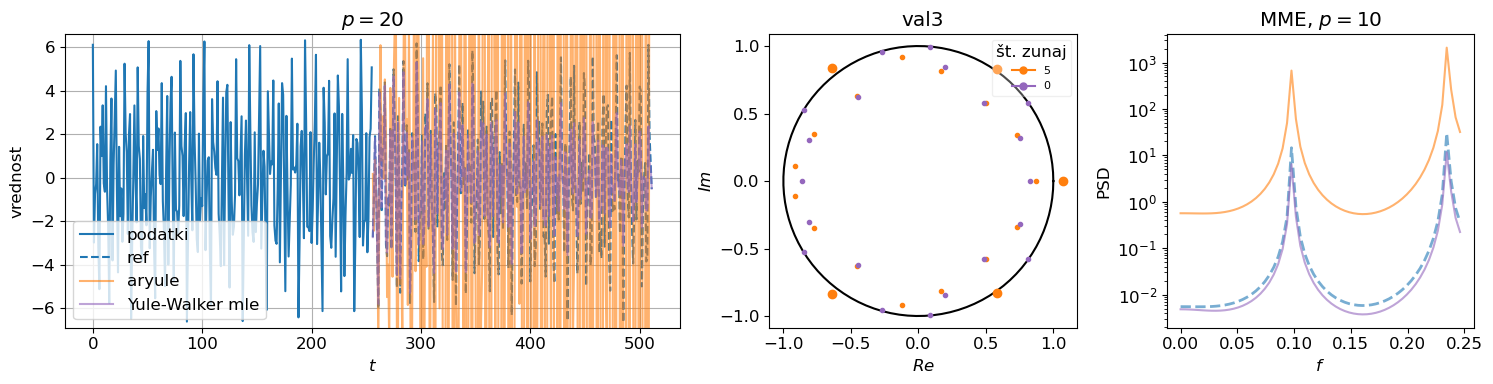

In [33]:
zamik = 0 #zamik od sredine
šum = 0 #standard deviation

#test datat
x=np.linspace(0,30,1000)
data = np.sin(2*np.pi*x) #+ np.sin(2*np.pi*x*1.2)
dim=len(x)
order = 5
ime ='test_sin'

#val2,3
val='3'
data = np.loadtxt('podatki/val'+val+'.dat')
dim=len(data)
x=np.linspace(0,dim-1,dim)
order = 20
ime = 'val'+str(val)

#co2
# x, data = np.loadtxt('podatki/co2.dat',unpack=True)
# dim=len(data)
# data[data==-99.99]= np.nan #missing value -> remove
# nan_indices = np.isnan(data)
# x = x[~nan_indices]
# data = data[~nan_indices]
# k=np.polyfit(x,data,deg=1)
# poli=np.poly1d(k)
# lin_trend=poli(x)
# data = data - lin_trend
# order = 20
# ime = 'co2'

if šum > 0:
        data += np.random.normal(scale=šum, size=dim)
meja = dim//2 + zamik
podatki,ref = data[:meja], data[meja:]
x1,x2 = x[:meja], x[meja:]

predict, poli = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=0, burg=False)
predict_zrc, poli_zrc = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=1, burg=False)
predict_b, poli_b = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=0, burg=True)
predict_yw, poli_yw = napoved_dat_yw(podatki, order=order, n_predict=len(ref), preslikaj=0, method='mle')
# napaka = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref)) #manj bolje
# print('napaka: ',napaka)

fig = plt.figure(figsize=(15, 4))
gs = fig.add_gridspec(1, 3, width_ratios=[2, 1, 1])
plt.subplots_adjust(wspace=0.5)

ax1 = fig.add_subplot(gs[:, 0])
ax1.plot(x1, podatki,label='podatki')
ax1.plot(x2,ref,'C0--',label='ref')
ax1.plot(x2,predict,'C1',label='aryule',alpha=0.6)
#ax1.plot(x2,predict_zrc,'C2',label='aryule zrcaljenje',alpha=0.6)
#ax1.plot(x2,predict_b,'C3',label='arburg',alpha=0.6)
ax1.plot(x2,predict_yw,'C4',label='Yule-Walker mle',alpha=0.6)

ax1.set_title('$p=$'+str(order))
ax1.legend(loc='lower left')
ax1.set_xlabel('$t$')
ax1.set_ylabel('vrednost')
ax1.set_ylim((min(data) - 0.25, max(data) + 0.25))
ax1.grid()

ax2 = fig.add_subplot(gs[:, 1])
phi = np.linspace(0, 2*np.pi, 100)
ax2.plot(np.cos(phi), np.sin(phi),'k')
n1=0
for i in range(len(poli)):
    r = np.abs(poli[i])
    if r > 1:
        n1+=1
        ax2.plot(poli[i].real, poli[i].imag, 'C1o')
    else:
        ax2.plot(poli[i].real, poli[i].imag, 'C1.')
n2=0
# for i in range(len(poli_zrc)):
#     r = np.abs(poli_zrc[i])
#     if r > 1:
#         n2+=1
#         ax2.plot(poli_zrc[i].real, poli_zrc[i].imag, 'C2o')
#     else:
#         ax2.plot(poli_zrc[i].real, poli_zrc[i].imag, 'C2.')
# n3=0
# for i in range(len(poli_b)):
#     r = np.abs(poli_b[i])
#     if r > 1:
#         n3+=1
#         ax2.plot(poli_b[i].real, poli_b[i].imag, 'C3o')
#     else:
#         ax2.plot(poli_b[i].real, poli_b[i].imag, 'C3.')
n4=0
for i in range(len(poli_yw)):
    r = np.abs(poli_yw[i])
    if r > 1:
        n4+=1
        ax2.plot(poli_yw[i].real, poli_yw[i].imag, 'C4o')
    else:
        ax2.plot(poli_yw[i].real, poli_yw[i].imag, 'C4.')
dot1 = mlines.Line2D([], [], color='C1', marker='o', markersize=5)
#dot2 = mlines.Line2D([], [], color='C2', marker='o', markersize=5)
#dot3 = mlines.Line2D([], [], color='C3', marker='o', markersize=5)
dot4 = mlines.Line2D([], [], color='C4', marker='o', markersize=5)
#ax2.legend(handles=[dot1, dot2, dot3, dot4], labels=(f'{n1}', f'{n2}',f'{n3}',f'{n4}'), title='št. zunaj', loc='upper right',framealpha=0.3,fontsize=8)
ax2.legend(handles=[dot1, dot4], labels=(f'{n1}',f'{n4}'), title='št. zunaj', loc='upper right',framealpha=0.3,fontsize=8)
ax2.axis('equal')
ax2.set_xlabel('$Re$')
ax2.set_ylabel('$Im$')

order_mme=10
PSD_mme = PSD_MME(ref, order=order_mme)/len(ref)
PSD_mme1 = PSD_MME(predict, order=order_mme)/len(predict)
PSD_mme2 = PSD_MME(predict_zrc.real, order=order_mme)/len(predict_zrc.real)
PSD_mme3 = PSD_MME(predict_b.real, order=order_mme)/len(predict_b.real)
PSD_mme4 = PSD_MME(predict_yw.real, order=order_mme)/len(predict_yw.real)
freq = np.fft.fftfreq(len(predict), d=x[1]-x[0])
dim=len(PSD_mme1)

ax3 = fig.add_subplot(gs[:, 2])
ax3.plot(freq[:dim//2], PSD_mme[:dim//2], 'C0--',linewidth=2,alpha=0.6)
ax3.plot(freq[:dim//2], PSD_mme1[:dim//2], 'C1',alpha=0.6)
#ax3.plot(freq[:dim//2], PSD_mme2[:dim//2], 'C2',alpha=0.6)
#ax3.plot(freq[:dim//2], PSD_mme3[:dim//2], 'C3',alpha=0.6)
ax3.plot(freq[:dim//2], PSD_mme4[:dim//2], 'C4',alpha=0.6)

plt.yscale('log')
ax3.set_xlabel('$f$')
ax3.set_ylabel('PSD')
ax3.set_title('MME, $p=$'+str(order_mme))

plt.tight_layout()
ax2.set_title(ime)
#plt.savefig('slike/'+ime+'.pdf')
#plt.savefig('slike/'+ime+'_šum'+str(šum)+'.pdf') #manjšanje reda pomaga proti preveliki amplitudi!
plt.show()

napaka:  0.8679404470716683


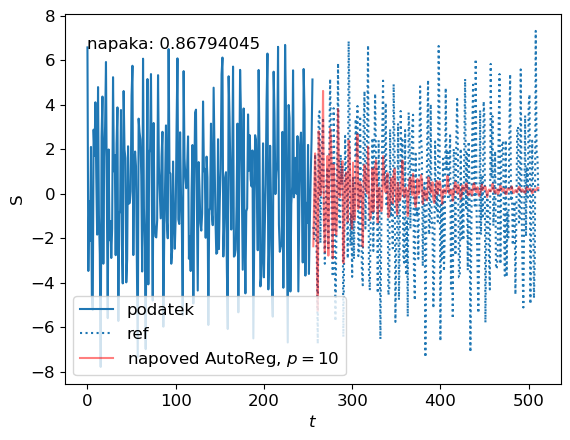

In [7]:
order=10
zamik = 0
šum = 1

# test data
x=np.linspace(0,30,1000)
data = np.sin(2*np.pi*x)
dim=len(data)

# val2,3
data = np.loadtxt('podatki/val3.dat', unpack=True)
dim=len(data)
x=np.linspace(0, dim-1, dim)

#co2
# x, data = np.loadtxt('podatki/co2.dat',unpack=True)
# dim=len(data)
# data[data==-99.99]= np.nan #missing value -> remove
# nan_indices = np.isnan(data)
# x = x[~nan_indices]
# data = data[~nan_indices]
# k=np.polyfit(x,data,deg=1)
# poli=np.poly1d(k)
# lin_trend=poli(x)
# data = data - lin_trend

if šum > 0:
        data += np.random.normal(scale=šum, size=dim)
meja = dim//2 + zamik
train, test = data[:meja], data[meja:]
x1, x2 = x[:meja], x[meja:]

predictions = napoved_AutoReg(train, order, n_predict=len(test))
napaka = np.sum(np.abs(test-predictions))/np.sum(np.abs(test))
print('napaka: ',napaka)

plt.plot(x1, train,label='podatek')
plt.plot(x2, test, 'C0:',label='ref')
plt.plot(x2, predictions, color='red',alpha=0.5,label='napoved AutoReg, $p=$'+str(order))
plt.text(0,6.5,'napaka: '+str(round(napaka,8)))
plt.legend()
plt.xlabel('$t$')
plt.ylabel('S')
#plt.savefig('slike/napoved_val3_autoreg.pdf')
plt.show()

In [5]:
# # je to ok?!
# data = np.loadtxt('podatki/val3.dat')
# R = autocorrelation(data,order=len(data))
# plt.plot(R,'.-')
# plt.title('autocorelation')

## napaka

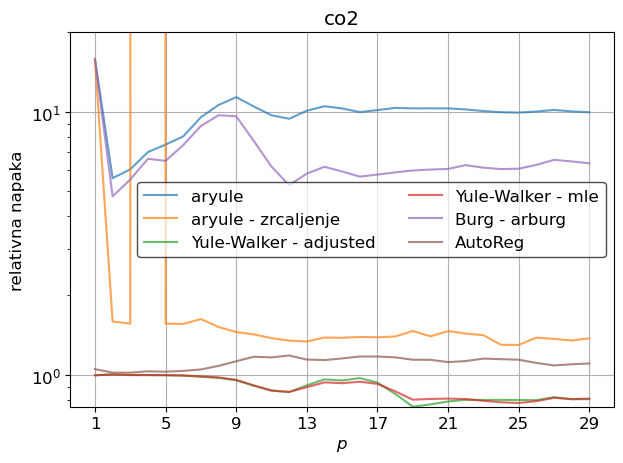

In [48]:
zamik = 0 #zamik od sredine

#test datat
x=np.linspace(0,30,1000)
data = np.sin(2*np.pi*x) #+ np.sin(2*np.pi*x*1.2)
dim=len(x)
ime = 'test_sin'

#val2,3
val = '3'
data = np.loadtxt('podatki/val'+val+'.dat')
dim=len(data)
x=np.linspace(0,dim-1,dim)
ime = 'val'+str(val)

#co2
x, data = np.loadtxt('podatki/co2.dat',unpack=True)
dim=len(data)
data[data==-99.99]= np.nan #missing value -> remove
nan_indices = np.isnan(data)
x = x[~nan_indices]
data = data[~nan_indices]
k=np.polyfit(x,data,deg=1)
poli=np.poly1d(k)
lin_trend=poli(x)
data = data - lin_trend
ime = 'co2'

meja = dim//2 + zamik
podatki,ref = data[:meja], data[meja:]
x1,x2 = x[:meja], x[meja:]

napaka1 =[]
napaka2 =[]
napaka3 =[]
napaka4=[]
napaka5=[]
napaka6=[]
red=np.arange(1,30,1,dtype=int)
for order in red:
    predict, _ = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=0, burg=False)
    err = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref))
    napaka1.append(err)
    predict, _ = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=1, burg=False)
    err = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref))
    napaka2.append(err)
    predict, _ = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=0, burg=True)
    err = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref))
    napaka3.append(err)
    predict, _ = napoved_dat_yw(podatki, order=order, n_predict=len(ref), method='adjusted')
    err = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref))
    napaka4.append(err)
    predict, _ = napoved_dat_yw(podatki, order=order, n_predict=len(ref), method='mle')
    err = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref))
    napaka5.append(err)
    predict = napoved_AutoReg(podatki, order, n_predict=len(ref))
    err = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref))
    napaka6.append(err)
# napaka4=np.array(napaka4)
# napaka4[napaka4>100]= np.nan #remove big error

plt.plot(red,napaka1,label='aryule',alpha=0.7) #pri val3, co2 napaka aprox 10!
plt.plot(red,napaka2,label='aryule - zrcaljenje',alpha=0.7) #ni ok - čudno
plt.plot(red,napaka4,'-',label='Yule-Walker - adjusted',alpha=0.7) #ni ok!, podivja, za co2 je ok
plt.plot(red,napaka5,label='Yule-Walker - mle',alpha=0.7)
plt.plot(red,napaka3,label='Burg - arburg',alpha=0.7) #pri co2 napaka aprox 10!, val3 - decrease order!
plt.plot(red,napaka6,label='AutoReg',alpha=0.7)

plt.yscale('log')
plt.ylim((min(np.concatenate((napaka1,napaka2,napaka3, napaka4, napaka5,napaka6))), 20))
plt.legend(loc='best',ncol=2,framealpha=0.7, edgecolor='black')
plt.xlabel('$p$')
plt.ylabel('relativna napaka')
plt.xticks(red[::4])
plt.title(ime)
plt.grid()
plt.tight_layout()
#plt.savefig('slike/napaka_'+ime+'.pdf')

# borza

napaka:  0.7080914912628777


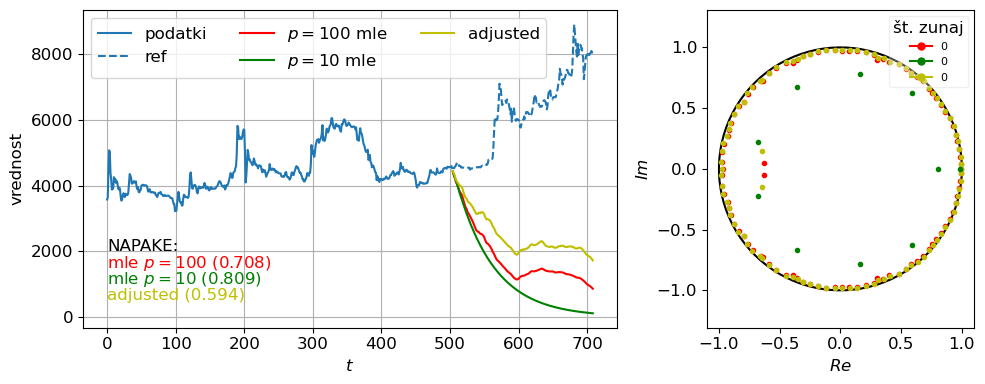

In [15]:
order = 100
zamik = 150 #zamik od sredine

data = np.loadtxt('podatki/borza.dat')
dim=len(data)
x=np.linspace(0,dim-1,dim)

meja = dim//2 + zamik
podatki,ref = data[:meja], data[meja:]
x1,x2 = x[:meja], x[meja:]

#predict, poli = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=0, burg=True) #ne dela!
predict, poli = napoved_dat_yw(podatki, order=order, n_predict=len(ref), method='mle') # dela
predict_10, poli_10 = napoved_dat_yw(podatki, order=10, n_predict=len(ref), method='mle') # dela
predict1, poli1 = napoved_dat_yw(podatki, order=order, n_predict=len(ref), method='adjusted') # dela
#predict, poli = napoved_AutoReg(train, order, n_predict=len(ref)), [] #ni ok
napaka = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref))
napaka1 = np.sum(np.abs(ref-predict1))/np.sum(np.abs(ref))
napaka10 = np.sum(np.abs(ref-predict_10))/np.sum(np.abs(ref))
print('napaka: ',napaka)

fig = plt.figure(figsize=(10, 4))
gs = fig.add_gridspec(1, 2, width_ratios=[2, 1])
plt.subplots_adjust(wspace=0.5)

ax1 = fig.add_subplot(gs[:, 0])
ax1.plot(x1, podatki,label='podatki')
ax1.plot(x2,ref,'C0--',label='ref')
ax1.plot(x2,predict,'r',label='$p=$'+str(order)+' mle')
ax1.plot(x2,predict_10,'g',label='$p=10$ mle')
ax1.plot(x2,predict1,'y',label='adjusted')
ax1.legend(loc='best',ncol=3)
ax1.set_xlabel('$t$')
ax1.set_ylabel('vrednost')
#ax1.set_ylim((min(data),max(data)))
ax1.grid()
ax1.text(0,2000, 'NAPAKE:')
ax1.text(0,1500, f'mle $p={{{order}}}$ ({round(napaka,3)})', color='r')
ax1.text(0,1000, f'mle $p=10$ ({round(napaka10,3)})',color='g')
ax1.text(0,500, f'adjusted ({round(napaka1,3)})',color='y')

ax2 = fig.add_subplot(gs[:, 1])
phi = np.linspace(0, 2*np.pi, 100)
ax2.plot(np.cos(phi), np.sin(phi),'k')
n=0
for i in range(len(poli)):
    r = np.abs(poli[i])
    if r > 1:
        n+=1
        ax2.plot(poli[i].real, poli[i].imag, 'ro')
    else:
        ax2.plot(poli[i].real, poli[i].imag, 'r.')
n1=0
for i in range(len(poli1)):
    r = np.abs(poli1[i])
    if r > 1:
        n1+=1
        ax2.plot(poli1[i].real, poli1[i].imag, 'yo')
    else:
        ax2.plot(poli1[i].real, poli1[i].imag, 'y.')
n2=0
for i in range(len(poli_10)):
    r = np.abs(poli_10[i])
    if r > 1:
        n2+=1
        ax2.plot(poli_10[i].real, poli_10[i].imag, 'go')
    else:
        ax2.plot(poli_10[i].real, poli_10[i].imag, 'g.')
red_dot = mlines.Line2D([], [], color='red', marker='o', markersize=5)
yellow_dot = mlines.Line2D([], [], color='y', marker='o', markersize=5)
green_dot = mlines.Line2D([], [], color='g', marker='o', markersize=5)
ax2.legend(handles=[red_dot, green_dot,yellow_dot], labels=(f'{n}',str(n2),f'{n1}'), title='št. zunaj', loc='upper right',framealpha=0.3,fontsize=8)
ax2.axis('equal')
ax2.set_xlabel('$Re$')
ax2.set_ylabel('$Im$')
plt.tight_layout()
#plt.savefig('slike/napoved_borza_zamik.pdf')
plt.show()

# luna

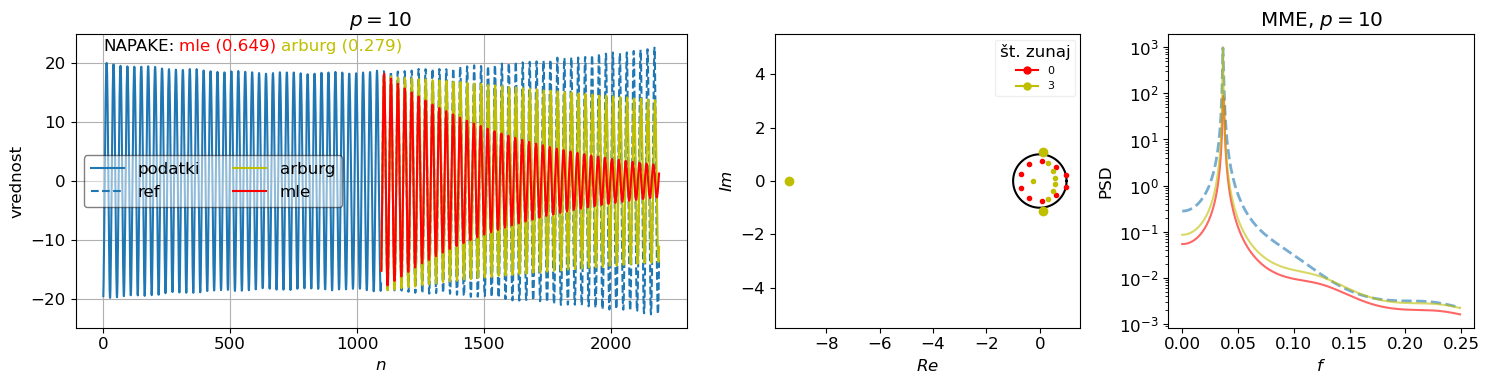

In [131]:
order = 10
zamik = 0 #zamik od sredine

data = np.loadtxt('podatki/luna.dat', usecols=(2))
dim=len(data)
x=np.linspace(0,dim-1,dim)

meja = dim//2 + zamik
podatki,ref = data[:meja], data[meja:]
x1,x2 = x[:meja], x[meja:]

#predict, poli = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=0, burg=False) #ni ok
predict, poli = napoved_dat_yw(podatki, order=order, n_predict=len(ref), method='mle') #djusted ni ok
predict1, poli1 = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=0, burg=True)
#predict, poli = napoved_AutoReg(train, order, n_predict=len(ref)), [] #zelo mala ampl.
napaka = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref))
napaka1 = np.sum(np.abs(ref-predict1))/np.sum(np.abs(ref))

fig = plt.figure(figsize=(15, 4))
gs = fig.add_gridspec(1, 3, width_ratios=[2, 1, 1])
plt.subplots_adjust(wspace=0.5)

ax1 = fig.add_subplot(gs[:, 0])
ax1.plot(x1, podatki,label='podatki')
ax1.plot(x2,ref,'C0--',label='ref')
ax1.plot(x2,(predict1),'y',label='arburg')
ax1.plot(x2,predict,'r',label='mle')
ax1.legend(loc='best',ncol=2,framealpha=0.5, edgecolor='black')
ax1.set_xlabel('$n$')
ax1.set_ylabel('vrednost')
#ax1.set_ylim((min(data),max(data)))
ax1.grid()
#ax1.text(0,22, f'NAPAKA: arburg({round(napaka,3)}), mle({round(napaka1,3)})')
ax1.text(0,22, 'NAPAKE:')
ax1.text(300,22, f'mle ({round(napaka,3)})', color='r')
ax1.text(700,22, f'arburg ({round(napaka1,3)})',color='y')
ax1.set_title('$p=$'+str(order))

ax2 = fig.add_subplot(gs[:, 1])
phi = np.linspace(0, 2*np.pi, 100)
ax2.plot(np.cos(phi), np.sin(phi),'k')
n=0
for i in range(len(poli)):
    r = np.abs(poli[i])
    if r > 1:
        n+=1
        ax2.plot(poli[i].real, poli[i].imag, 'ro')
    else:
        ax2.plot(poli[i].real, poli[i].imag, 'r.')
n1=0
for i in range(len(poli1)):
    r = np.abs(poli1[i])
    if r > 1:
        n1+=1
        ax2.plot(poli1[i].real, poli1[i].imag, 'yo')
    else:
        ax2.plot(poli1[i].real, poli1[i].imag, 'y.')
red_dot = mlines.Line2D([], [], color='red', marker='o', markersize=5)
yellow_dot = mlines.Line2D([], [], color='y', marker='o', markersize=5)
ax2.legend(handles=[red_dot, yellow_dot], labels=(f'{n}', f'{n1}'), title='št. zunaj', loc='upper right',fontsize=8, framealpha=0.3)
ax2.axis('equal')
ax2.set_xlabel('$Re$')
ax2.set_ylabel('$Im$')

order_mme=10
PSD_mme = PSD_MME(ref, order=order_mme)/len(ref)
PSD_mme1 = PSD_MME(predict, order=order_mme)/len(predict)
PSD_mme2 = PSD_MME(predict1.real, order=order_mme)/len(predict1.real)
freq = np.fft.fftfreq(len(predict), d=x[1]-x[0])
dim=len(PSD_mme1)

ax3 = fig.add_subplot(gs[:, 2])
ax3.plot(freq[:dim//2], PSD_mme[:dim//2], 'C0--',linewidth=2,alpha=0.6)
ax3.plot(freq[:dim//2], PSD_mme1[:dim//2], 'r',alpha=0.6)
ax3.plot(freq[:dim//2], PSD_mme2[:dim//2], 'y',alpha=0.6)

plt.yscale('log')
ax3.set_xlabel('$f$')
ax3.set_ylabel('PSD')
ax3.set_title('MME, $p=$'+str(order_mme))

plt.tight_layout()
#plt.savefig('slike/napoved_luna.pdf')
plt.show()

# Wolf

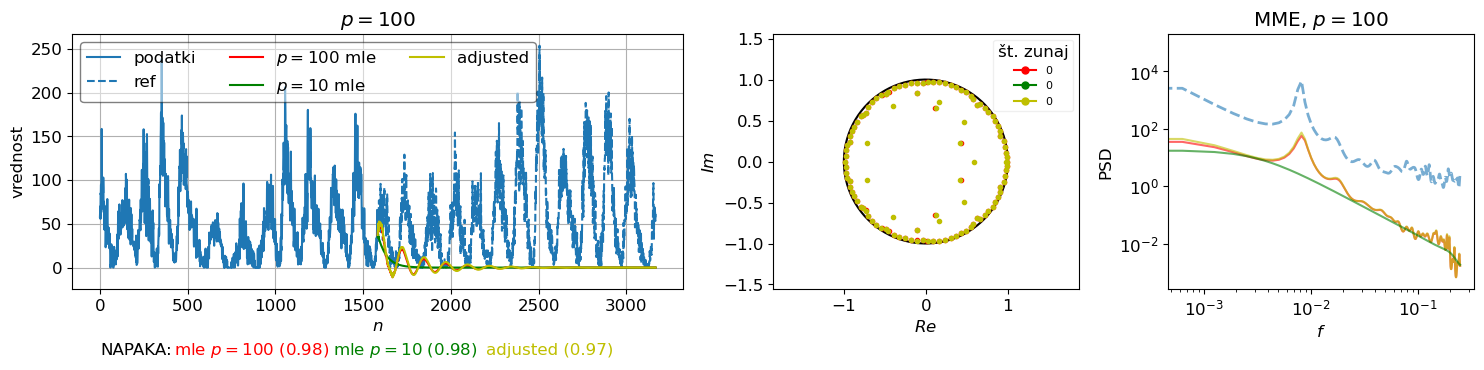

In [132]:
order = 100
order2= 10
zamik = 0 #zamik od sredine

y,m,data = np.loadtxt('podatki/Wolf_number.dat',unpack=True)
dim=len(data)
x=np.linspace(0,dim-1,dim)

meja = dim//2 + zamik
podatki,ref = data[:meja], data[meja:]
x1,x2 = x[:meja], x[meja:]

#predict, poli = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=1, burg=False) #ni ok
predict, poli = napoved_dat_yw(podatki, order=order, n_predict=len(ref), method='mle') #oboje podobno
predict2, poli2 = napoved_dat_yw(podatki, order=order2, n_predict=len(ref), method='mle') #oboje podobno
predict1, poli1 = napoved_dat_yw(podatki, order=order, n_predict=len(ref), method='adjusted') #oboje podobno
#predict, poli = napoved_AutoReg(train, order, n_predict=len(ref)), [] #mala ampl.
napaka = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref))
napaka1 = np.sum(np.abs(ref-predict1))/np.sum(np.abs(ref))
napaka2 = np.sum(np.abs(ref-predict2))/np.sum(np.abs(ref))

fig = plt.figure(figsize=(15, 4))
gs = fig.add_gridspec(1, 3, width_ratios=[2, 1, 1])
plt.subplots_adjust(wspace=0.5)

ax1 = fig.add_subplot(gs[:, 0])
ax1.plot(x1, podatki,label='podatki')
ax1.plot(x2,ref,'C0--',label='ref')
ax1.plot(x2,predict,'r',label='$p=$'+str(order)+' mle')
ax1.plot(x2,predict2,'g',label='$p=$'+str(order2)+' mle')
ax1.plot(x2,predict1,'y',label='adjusted')
ax1.legend(loc='best',ncol=3,framealpha=0.5, edgecolor='black')
ax1.set_xlabel('$n$')
ax1.set_ylabel('vrednost')
#ax1.set_ylim((min(data),max(data)))
ax1.grid()
ax1.text(0,-100, f'NAPAKA:')
ax1.text(420,-100, f'mle $p={{{order}}}$ ({round(napaka,2)})', color='r')
ax1.text(1330,-100, f'mle $p={{{order2}}}$ ({round(napaka2,2)})',color='g')
ax1.text(2200,-100, f'adjusted ({round(napaka1,2)})',color='y')
ax1.set_title('$p=$'+str(order))

ax2 = fig.add_subplot(gs[:, 1])
phi = np.linspace(0, 2*np.pi, 100)
ax2.plot(np.cos(phi), np.sin(phi),'k')
n=0
for i in range(len(poli)):
    r = np.abs(poli[i])
    if r > 1:
        n+=1
        ax2.plot(poli[i].real, poli[i].imag, 'ro')
    else:
        ax2.plot(poli[i].real, poli[i].imag, 'r.')
n1=0
for i in range(len(poli1)):
    r = np.abs(poli1[i])
    if r > 1:
        n1+=1
        ax2.plot(poli1[i].real, poli1[i].imag, 'yo')
    else:
        ax2.plot(poli1[i].real, poli1[i].imag, 'y.')
n2=0
for i in range(len(poli2)):
    r = np.abs(poli2[i])
    if r > 1:
        n2+=1
        ax2.plot(poli2[i].real, poli2[i].imag, 'yo')
    else:
        ax2.plot(poli2[i].real, poli2[i].imag, 'y.')
red_dot = mlines.Line2D([], [], color='red', marker='o', markersize=5)
yellow_dot = mlines.Line2D([], [], color='y', marker='o', markersize=5)
green_dot = mlines.Line2D([], [], color='g', marker='o', markersize=5)
ax2.legend(handles=[red_dot, green_dot, yellow_dot], labels=(f'{n}', str(n2),f'{n1}'), title='št. zunaj', loc='upper right', fontsize=8,framealpha=0.3)
ax2.axis('equal')
ax2.set_xlabel('$Re$')
ax2.set_ylabel('$Im$')

order_mme=100
PSD_mme = PSD_MME(ref, order=order_mme)/len(ref)
PSD_mme1 = PSD_MME(predict.real, order=order_mme)/len(predict.real)
PSD_mme2 = PSD_MME(predict1.real, order=order_mme)/len(predict1.real)
PSD_mme3 = PSD_MME(predict2.real, order=order_mme)/len(predict2.real)
freq = np.fft.fftfreq(len(predict), d=x[1]-x[0])
dim=len(PSD_mme1)

ax3 = fig.add_subplot(gs[:, 2])
ax3.plot(freq[:dim//2], PSD_mme[:dim//2], 'C0--',linewidth=2,alpha=0.6)
ax3.plot(freq[:dim//2], PSD_mme1[:dim//2], 'r',alpha=0.6)
ax3.plot(freq[:dim//2], PSD_mme2[:dim//2], 'y',alpha=0.6)
ax3.plot(freq[:dim//2], PSD_mme3[:dim//2], 'g',alpha=0.6)

ax3.set_yscale('log')
ax3.set_xscale('log')
ax3.set_xlabel('$f$')
ax3.set_ylabel('PSD')
ax3.set_title('MME, $p=$'+str(order_mme))

plt.tight_layout()
#plt.savefig('slike/napoved_wolf.pdf')
plt.show()

# temp

347 max order


/tmp/ipykernel_149624/3041569544.py:109: RuntimeWarning: divide by zero encountered in divide
  ax3.plot(1/freq_r[:dim//2], PSD_2r[:dim//2], label='MME ref')
/tmp/ipykernel_149624/3041569544.py:111: RuntimeWarning: divide by zero encountered in divide
  ax3.plot(1/freq[:dim//2], PSD_mme1[:dim//2], 'y',label='$p=$'+str(order)+' mle')
/tmp/ipykernel_149624/3041569544.py:112: RuntimeWarning: divide by zero encountered in divide
  ax3.plot(1/freq[:dim//2], PSD_mme2[:dim//2], 'g',label='$p=100$ mle')
/tmp/ipykernel_149624/3041569544.py:113: RuntimeWarning: divide by zero encountered in divide
  ax3.plot(1/freq[:dim//2], PSD_mme[:dim//2], 'r',label='arburg')


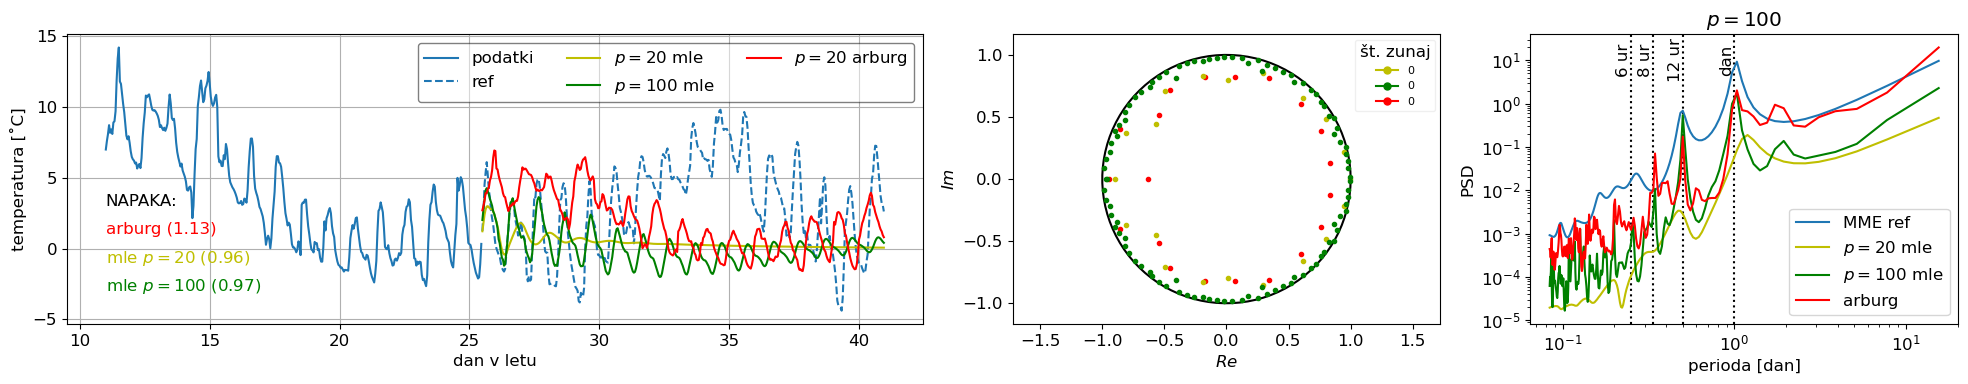

In [141]:
n=30 #prikaz dni
z=10 #zamik dni
order= 20

convert_nan = lambda x: np.nan if x.strip() == b'' else float(x)
y = np.loadtxt('podatki/temp.csv', skiprows=10, usecols=1, delimiter=',', converters={1: convert_nan})
dim=len(y)
x=np.linspace(0,dim-1,dim) #hours
days = x/24+1
data = np.interp(x, np.where(~np.isnan(y))[0], y[~np.isnan(y)])
data = data[z*24:z*24+24*n]
x = days[z*24:z*24+24*n]
dim=len(data)

meja = dim//2-12
podatki,ref = data[:meja], data[meja:]
x1,x2 = x[:meja], x[meja:]
print(len(podatki)-1, 'max order')

predict, poli = napoved_dat(podatki, order=order, n_predict=len(ref), preslikaj=1, burg=True) #ni ok
predict1, poli1 = napoved_dat_yw(podatki, order=order, n_predict=len(ref), method='mle') #oboje podobno
predict2, poli2 = napoved_dat_yw(podatki, order=100, n_predict=len(ref), method='mle') #oboje podobno
#predict, poli = napoved_AutoReg(train, order, n_predict=len(ref)), [] #mala ampl.
napaka = np.sum(np.abs(ref-predict))/np.sum(np.abs(ref))
napaka1 = np.sum(np.abs(ref-predict1))/np.sum(np.abs(ref))
napaka2 = np.sum(np.abs(ref-predict2))/np.sum(np.abs(ref))

fig = plt.figure(figsize=(20, 4))
gs = fig.add_gridspec(1, 3, width_ratios=[2, 1, 1])
plt.subplots_adjust(wspace=0.5)

ax1 = fig.add_subplot(gs[:, 0])
ax1.plot(x1, podatki,label='podatki')
ax1.plot(x2,ref,'C0--',label='ref')
ax1.plot(x2,predict1,'y',label='$p=$'+str(order)+' mle')
ax1.plot(x2,predict2,'g',label='$p=100$ mle')
ax1.plot(x2,predict,'r',label='$p=$'+str(order)+' arburg')
ax1.legend(loc='best',ncol=3,framealpha=0.5, edgecolor='black')
ax1.set_xlabel('dan v letu')
ax1.set_ylabel('temperatura [˚C]')
#ax1.set_ylim((min(data),max(data)))
ax1.grid()
ax1.text(x[0],3, f'NAPAKA:')
ax1.text(x[0],1, f'arburg ({round(napaka,2)})',color='r')
ax1.text(x[0],-1, f'mle $p=${order} ({round(napaka1,2)})',color='y')
ax1.text(x[0],-3, f'mle $p=100$ ({round(napaka2,2)})',color='g')

ax2 = fig.add_subplot(gs[:, 1])
phi = np.linspace(0, 2*np.pi, 100)
ax2.plot(np.cos(phi), np.sin(phi),'k')
n=0
for i in range(len(poli)):
    r = np.abs(poli[i])
    if r > 1:
        n+=1
        ax2.plot(poli[i].real, poli[i].imag, 'ro')
    else:
        ax2.plot(poli[i].real, poli[i].imag, 'r.')
n1=0
for i in range(len(poli1)):
    r = np.abs(poli1[i])
    if r > 1:
        n1+=1
        ax2.plot(poli1[i].real, poli1[i].imag, 'yo')
    else:
        ax2.plot(poli1[i].real, poli1[i].imag, 'y.')
n2=0
for i in range(len(poli2)):
    r = np.abs(poli2[i])
    if r > 1:
        n2+=1
        ax2.plot(poli2[i].real, poli2[i].imag, 'go')
    else:
        ax2.plot(poli2[i].real, poli2[i].imag, 'g.')
red_dot = mlines.Line2D([], [], color='red', marker='o', markersize=5)
yellow_dot = mlines.Line2D([], [], color='y', marker='o', markersize=5)
green_dot = mlines.Line2D([], [], color='g', marker='o', markersize=5)
ax2.legend(handles=[yellow_dot,green_dot, red_dot], labels=(f'{n1}', f'{n2}',f'{n}'), title='št. zunaj', loc='upper right', fontsize=8,framealpha=0.3)
ax2.axis('equal')
ax2.set_xlabel('$Re$')
ax2.set_ylabel('$Im$')

f=np.fft.fft(ref)
freq_r = np.fft.fftfreq(len(ref), d=x[1]-x[0])
PSD_r = np.abs(f)**2/len(ref)
PSD_2r = PSD_MME(ref, order=order)/len(ref)

f=np.fft.fft(predict)
freq = np.fft.fftfreq(len(predict), d=x[1]-x[0])
PSD = np.abs(f)**2/len(predict)

order_mme=100
PSD_mme1 = PSD_MME(predict1, order=order_mme)/len(predict1)
PSD_mme2 = PSD_MME(predict2, order=order_mme)/len(predict1)
PSD_mme = PSD_MME(predict.real, order=order_mme)/len(predict1) #predict je complex!

dim=len(predict)
ax3 = fig.add_subplot(gs[:, 2])
ax3.axvline(1, color='k', linestyle='dotted')
ax3.text(1, 10, 'dan', color='k', ha='right', va='center', rotation='vertical')
ax3.axvline(0.5, color='k', linestyle='dotted')
ax3.text(0.5, 10, '12 ur', color='k', ha='right', va='center', rotation='vertical')
ax3.axvline(1/3, color='k', linestyle='dotted')
ax3.text(1/3, 10, '8 ur', color='k', ha='right', va='center', rotation='vertical')
ax3.axvline(0.25, color='k', linestyle='dotted')
ax3.text(0.25, 10, '6 ur', color='k', ha='right', va='center', rotation='vertical')

#ax3.plot(1/freq_r[:dim//2], PSD_r[:dim//2], label='FFT ref')
ax3.plot(1/freq_r[:dim//2], PSD_2r[:dim//2], label='MME ref')
#ax3.plot(1/freq[:dim//2], PSD[:dim//2],label='FFT predict')
ax3.plot(1/freq[:dim//2], PSD_mme1[:dim//2], 'y',label='$p=$'+str(order)+' mle')
ax3.plot(1/freq[:dim//2], PSD_mme2[:dim//2], 'g',label='$p=100$ mle')
ax3.plot(1/freq[:dim//2], PSD_mme[:dim//2], 'r',label='arburg')

ax3.legend()
ax3.set_title('$p=$'+str(order_mme))
ax3.set_xlabel('perioda [dan]')
ax3.set_ylabel('PSD')
ax3.set_xscale('log')
ax3.set_yscale('log')

plt.tight_layout()
#plt.savefig('slike/temp_dnevna_napoved.pdf')
plt.show()